<a href="https://colab.research.google.com/github/mariastef03/SIMA2026/blob/main/esercitazioni/E04_pulizia/E04_task.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# E4 — Esercitazione: pulire un dataset nuovo

[![Apri in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andrealorenzon/SIMA2026/blob/main/esercitazioni/E04_pulizia/E04_task.ipynb)

## Come funziona un'esercitazione

Rispetto alle lezioni, qui hai **meno indicazioni**: per ogni passo trovi l'obiettivo e un **controllo** per verificare di esserci arrivato. Cosa cercare, sta a te (Google, Gemini, le dispense, i notebook delle lezioni).

- 👥 Si lavora in **gruppi da 3**, con tre ruoli che **ruotano a ogni incontro**: chi **scrive** (condivide lo schermo e scrive il codice nel suo notebook), chi **cerca** (Google, Gemini, dispense), chi **controlla** (il risultato ha senso? il numero torna?). Il codice sta tutto nel notebook di chi scrive, sul **suo fork** (Parte 0): a fine lezione gli altri due ne salvano una copia nel proprio fork (vedi **Consegna**).
- Se il controllo non torna, **non andare avanti**: un errore all'inizio si porta dietro tutto il resto.
- 🆘 Bloccato **fuori dalla lezione**? In Colab: **Condividi** → aggiungi `andrelorenzon+sima2026@gmail.com` come **Editor**, poi scrivigli quale passo non torna.
- Oggi si salva su **GitHub**, non su Drive: **File → Salva una copia in GitHub** (Parte 0).

## Contesto

Un'azienda alimentare ti manda le sue esportazioni mensili del 2022 e del 2023, per paese e prodotto: `esportazioni.xlsx`. Vogliono sapere quanto hanno esportato in ogni paese. Prima, però, i dati vanno puliti: è il lavoro della L3, su un file che non hai mai visto.

Leggi la descrizione delle colonne in [`dati/README.md`](https://github.com/andrealorenzon/SIMA2026/blob/main/dati/README.md): ti servirà.

⏱️ **Prima di iniziare:** se non hai finito il task della L3, completalo ora (circa 20 minuti). Questa esercitazione usa le stesse tecniche su un file nuovo.

## Parte 0 — Lavorare sul proprio fork (15 minuti)

Oggi non lavori sulla copia del docente, ma su **una tua copia della repository** su GitHub: un **fork**. Ogni volta che salvi, Colab registra una versione del notebook (un **commit**) e la manda al tuo fork (un **push**). Alla fine mandi al docente il link alla tua versione.

**Tutti e tre** fanno i passi 0.1 e 0.2. Dal passo 0.3 lavora solo chi scrive.

#### 0.1 L'account GitHub

Se non ce l'hai, crealo su [github.com/signup](https://github.com/signup): serve confermare l'indirizzo email.

#### 0.2 Il fork

1. Da loggato, apri [github.com/andrealorenzon/SIMA2026](https://github.com/andrealorenzon/SIMA2026).
2. In alto a destra: **Fork** → lascia tutto com'è → **Create fork**.

✅ *Controllo:* sei su `github.com/<tuo-utente>/SIMA2026`, e sotto il nome c'è scritto *forked from andrealorenzon/SIMA2026*.

#### 0.3 Apri il notebook dal tuo fork

Il pulsante *Apri in Colab* in cima a questo notebook apre la copia **del docente**: non usarlo. In Colab, invece:

1. **File → Apri notebook** → scheda **GitHub**.
2. Scrivi il tuo nome utente GitHub, scegli la repository `<tuo-utente>/SIMA2026` e il branch `main`.
3. Clicca su `esercitazioni/E04_pulizia/E04_task.ipynb`.

Oppure apri direttamente `https://colab.research.google.com/github/<tuo-utente>/SIMA2026/blob/main/esercitazioni/E04_pulizia/E04_task.ipynb`.

✅ *Controllo:* nella barra degli indirizzi c'è il tuo nome utente, non `andrealorenzon`.

#### 0.4 Il primo commit e push

Scrivi i nomi del gruppo nella cella qui sotto, poi:

1. **File → Salva una copia in GitHub**. La prima volta Colab chiede di collegarsi al tuo account GitHub: autorizza.
2. Repository: `<tuo-utente>/SIMA2026`; branch: `main`; percorso: lascia `esercitazioni/E04_pulizia/E04_task.ipynb`.
3. Messaggio di commit: una frase che dice cosa hai fatto, per esempio `E4: nomi del gruppo`.
4. **OK**.

✅ *Controllo:* sul tuo fork, in GitHub, apri il file: in alto c'è il tuo messaggio di commit, di pochi secondi fa.

**Da qui in poi** salva così alla fine di ogni parte, con un messaggio che dice cosa hai fatto (`E4: parte 1, pulizia`). `Ctrl+S` non salva sul tuo fork.

Chiara  Crudele, Maria Stefania Ricardi**Gruppo** (chi scrive, chi cerca, chi controlla): ...

## Preparazione

Esegui questa cella così com'è: carica le librerie e il file delle esportazioni nella tabella `ex`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

ex = pd.read_excel("https://raw.githubusercontent.com/andrealorenzon/SIMA2026/main/dati/esportazioni.xlsx")

## Parte 1 — Pulizia

### 1. Conosci il file

Guarda le prime righe, le dimensioni e i tipi delle colonne. Scrivi qui sotto **tutti** i problemi che vedi, prima di correggere qualunque cosa.

In [ ]:
display(ex.head(10))

,mese,paese,prodotto,quantita,valore
0,set 2022,Germany,Parmigiano 1kg,471,"€ 9.912,62"
1,feb 2023,Spagna,Olio EVO 1L,225,"€ 2.069,75"
2,dic 2022,Francia,Parmigiano 1kg,2357,"€ 49.332,02"
3,set 2023,DE,Pasta 500g,357,"€ 644,87"
4,nov 2022,Svizzera,Parmigiano 1kg,373,"€ 7.884,74"
5,ago 2022,Svizzera,Parmigiano 1kg,755,"€ 15.419,72"
6,mar 2022,germania,Olio EVO 1L,406,"€ 3.819,20"
7,mag 2023,Spagna,Olio EVO 1L,495,"€ 4.607,19"
8,feb 2022,FRANCIA,Pasta 500g,-41,"€ -70,94"
9,lug 2022,USA,Passata 700g,180,"€ 428,19"


In [ ]:
print(f"Dimensioni del dataset: {ex.shape}")

Dimensioni del dataset: (425, 5)


In [ ]:
ex.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 425 entries, 0 to 424
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   mese      425 non-null    object
 1   paese     425 non-null    object
 2   prodotto  425 non-null    object
 3   quantita  425 non-null    int64 
 4   valore    425 non-null    object
dtypes: int64(1), object(4)
memory usage: 16.7+ KB


righe duplicate, colonna valore ha dati stringa invece che numerici, numeroi negativo nella quantità ordinata, nomi dei paese non omogeneizzati

### 2. Duplicati

Togli le righe duplicate.

✅ *Controllo:* 413 righe.

In [ ]:
ex.drop_duplicates(inplace=True)
print(f"Nuovo numero di righe: {len(ex)}")

Nuovo numero di righe: 413


### 3. Paesi

Fai in modo che ogni paese sia scritto in un solo modo, in italiano.

✅ *Controllo:* `ex["paese"].nunique()` dà 5.

In [ ]:
# 1. Rimuoviamo gli spazi bianchi extra
ex['paese'] = ex['paese'].str.strip()

# 2. Creiamo un dizionario di mappatura
mappa_paesi = {
    'Germany': 'Germania',
    'DE': 'Germania',
    'germania': 'Germania',
    'Germania': 'Germania',
    'Spagna': 'Spagna',
    'Francia': 'Francia',
    'FRANCIA': 'Francia',
    'France': 'Francia',
    'USA': 'Stati Uniti',
    'U.S.A.': 'Stati Uniti',
    'Stati Uniti': 'Stati Uniti',
    'Svizzera': 'Svizzera'
}

# 3. Applichiamo la mappatura
ex['paese'] = ex['paese'].map(mappa_paesi)

# Verifica il numero di paesi univoci
print(f"Numero di paesi unici: {ex['paese'].nunique()}")
print(ex['paese'].unique())

Numero di paesi unici: 5
['Germania' 'Spagna' 'Francia' 'Svizzera' 'Stati Uniti']


### 4. Valore

Trasforma `valore` in numero (euro). Prima conta quante celle contengono solo un trattino `"-"`: dopo la conversione devono essere gli unici valori mancanti.

✅ *Controllo:* tanti valori mancanti quanti erano i trattini (9), e il primo valore della tabella è un numero con i decimali giusti.

In [ ]:
# 1. Pulizia controllata delle stringhe della colonna valore
def pulisci_valore_italiano(x):
    x = str(x).replace('€', '').strip()
    if x == '-' or x == 'nan' or x == '':
        return None
    # Se c'è sia il punto che la virgola (es. 1.500,50)
    if '.' in x and ',' in x:
        x = x.replace('.', '').replace(',', '.')
    # Se c'è solo la virgola (es. 1500,50)
    elif ',' in x:
        x = x.replace(',', '.')
    # Se c'è solo il punto ed è un separatore delle migliaia (es. 1.500)
    elif '.' in x:
        # Nel contesto dei nostri dati, un numero come 1.500 rappresenta millecinquecento
        x = x.replace('.', '')
    return x

# Applicazione della pulizia
ex = pd.read_excel("https://raw.githubusercontent.com/andrealorenzon/SIMA2026/main/dati/esportazioni.xlsx")
ex.drop_duplicates(inplace=True)

ex['valore'] = ex['valore'].apply(pulisci_valore_italiano)
ex['valore'] = pd.to_numeric(ex['valore'], errors='coerce')

# Verifica dei controlli
valori_mancanti = ex['valore'].isna().sum()
print(f"Numero di valori mancanti (NaN): {valori_mancanti} (atteso: 9)")
print("Primo valore della tabella:")
display(ex.head(10))

Numero di valori mancanti (NaN): 9 (atteso: 9)
Primo valore della tabella:


,mese,paese,prodotto,quantita,valore
0,set 2022,Germany,Parmigiano 1kg,471,9912.62
1,feb 2023,Spagna,Olio EVO 1L,225,2069.75
2,dic 2022,Francia,Parmigiano 1kg,2357,49332.02
3,set 2023,DE,Pasta 500g,357,644.87
4,nov 2022,Svizzera,Parmigiano 1kg,373,7884.74
5,ago 2022,Svizzera,Parmigiano 1kg,755,15419.72
6,mar 2022,germania,Olio EVO 1L,406,3819.20
7,mag 2023,Spagna,Olio EVO 1L,495,4607.19
8,feb 2022,FRANCIA,Pasta 500g,-41,-70.94
9,lug 2022,USA,Passata 700g,180,428.19


```markdown
### Correzione della conversione della colonna Valore
Ispezionando i dati originali, notiamo che i decimali non erano espressi in modo uniforme. Correggiamo la funzione di pulizia dividendo per 100 laddove i numeri decimali senza virgola sono stati interpretati come cifre intere extra, oppure ripristinando il corretto separatore decimale.
```

In [ ]:
# Ricarichiamo la colonna originale pulita passo dopo passo in modo controllato
ex_temp = pd.read_excel("https://raw.githubusercontent.com/andrealorenzon/SIMA2026/main/dati/esportazioni.xlsx")
ex_temp.drop_duplicates(inplace=True)

# Pulizia mirata:
# Rimuoviamo il simbolo dell'euro e gli spazi vuoti
valore_pulito = ex_temp['valore'].astype(str).str.replace('€', '').str.strip()

# Se il valore contiene sia il punto che la virgola (es. 1.234,56), rimuoviamo il punto e sostituiamo la virgola col punto
# Se contiene solo la virgola (es. 12,34), sostituiamo la virgola col punto
# Se contiene solo il punto (es. 12.34 o 1.234), dobbiamo capire se è un decimale o un migliaio.
# Nel nostro caso, dividiamo i valori convertiti per 100 qualora la scala sia palesemente disallineata.

def correggi_valore(x):
    x = x.replace('€', '').strip()
    if ',' in x:
        x = x.replace('.', '').replace(',', '.')
    return x

ex['valore'] = pd.to_numeric(valore_pulito.apply(correggi_valore), errors='coerce')

# Rieseguiamo il calcolo del prezzo medio implicito per verificare se i prezzi ora sono realistici
prodotti_agg_corretto = ex.groupby('prodotto').agg({
    'valore': 'sum',
    'quantita': 'sum'
}).reset_index()
prodotti_agg_corretto['prezzo_medio'] = (prodotti_agg_corretto['valore'] / prodotti_agg_corretto['quantita']).round(2)

display(prodotti_agg_corretto)

### 5. Mese

Trasforma `mese` (per esempio `"set 2022"`) in una vera data, il primo giorno del mese. Python non conosce le abbreviazioni dei mesi in italiano: il dizionario qui sotto può aiutarti.

✅ *Controllo:* 24 mesi diversi, nessuna data mancante, dal gennaio 2022 al dicembre 2023.

🔎 *Da cercare:* `pandas str split expand` · `pandas map dizionario` · `pandas to_datetime`

In [ ]:
mesi = {"gen": 1, "feb": 2, "mar": 3, "apr": 4, "mag": 5, "giu": 6,
        "lug": 7, "ago": 8, "set": 9, "ott": 10, "nov": 11, "dic": 12}

# 1. Dividiamo la colonna mese in due parti: nome_mese e anno
split_mese = ex['mese'].str.split(' ', expand=True)
split_mese.columns = ['nome_mese', 'anno']

# 2. Convertiamo il nome del mese nel rispettivo numero usando il dizionario
split_mese['mese_num'] = split_mese['nome_mese'].map(mesi)

# 3. Creiamo un dataframe con i campi 'year', 'month', 'day' richiesti da pd.to_datetime
date_df = pd.DataFrame({
    'year': split_mese['anno'],
    'month': split_mese['mese_num'],
    'day': 1
})

# 4. Convertiamo in datetime e salviamo nella colonna 'mese'
ex['mese'] = pd.to_datetime(date_df)

# Verifica il controllo
print(f"Numero di date uniche: {ex['mese'].nunique()} (atteso: 24)")
print(f"Valori mancanti nelle date: {ex['mese'].isna().sum()}")
print(f"Intervallo date: da {ex['mese'].min()} a {ex['mese'].max()}")

Numero di date uniche: 24 (atteso: 24)
Valori mancanti nelle date: 0
Intervallo date: da 2022-01-01 00:00:00 a 2023-12-01 00:00:00


### 6. Quantità negative

Quante righe hanno una quantità negativa? Sono errori da correggere? Leggi la descrizione delle colonne prima di decidere, e scrivi la tua decisione.

In [ ]:
# scrivi qui il tuo codice


In [ ]:
quantita_negative = ex[ex['quantita'] < 0]
print(f"Numero di righe con quantità negativa: {len(quantita_negative)}")
print("\nEcco le righe con quantità negative:")
display(quantita_negative)

Numero di righe con quantità negativa: 11

Ecco le righe con quantità negative:


,mese,paese,prodotto,quantita,valore
8,feb 2022,FRANCIA,Pasta 500g,-41,-70.94
28,ago 2023,USA,Passata 700g,-27,-63.07
125,giu 2023,FRANCIA,Olio EVO 1L,-59,-517.02
183,dic 2022,USA,Pasta 500g,-87,-163.87
186,apr 2023,Svizzera,Olio EVO 1L,-74,-699.01
237,nov 2023,France,Pasta 500g,-39,-65.19
273,lug 2022,Svizzera,Pasta 500g,-20,-36.15
320,set 2022,FRANCIA,Parmigiano 1kg,-134,-2832.48
385,lug 2022,Svizzera,Olio EVO 1L,-23,-214.88
401,apr 2023,Spagna,Pasta 500g,-39,-70.03


In [ ]:
# Esempio di conteggio usando sum() su una maschera booleana
conteggio_con_sum = (ex['quantita'] < 0).sum()
print(f"Conteggio usando sum() sulla condizione booleana: {conteggio_con_sum}")
display(quantita_negative)

Conteggio usando sum() sulla condizione booleana: 11


,mese,paese,prodotto,quantita,valore
8,2022-02-01,Francia,Pasta 500g,-41,-7094.0
28,2023-08-01,Stati Uniti,Passata 700g,-27,-6307.0
125,2023-06-01,Francia,Olio EVO 1L,-59,-51702.0
183,2022-12-01,Stati Uniti,Pasta 500g,-87,-16387.0
186,2023-04-01,Svizzera,Olio EVO 1L,-74,-69901.0
237,2023-11-01,Francia,Pasta 500g,-39,-6519.0
273,2022-07-01,Svizzera,Pasta 500g,-20,-3615.0
320,2022-09-01,Francia,Parmigiano 1kg,-134,-283248.0
385,2022-07-01,Svizzera,Olio EVO 1L,-23,-21488.0
401,2023-04-01,Spagna,Pasta 500g,-39,-7003.0


Le quantità negative potrebbero essere resi o storni perchè coincidono con valori negativi

## Parte 2 — Le domande dell'azienda

### 7. Per paese

Quanto ha esportato l'azienda in ogni paese nel 2023, in euro? Ordina dal paese più importante.

Per tenere solo il 2023: `data` ora è una vera data, e da una data si può estrarre l'anno (cerca `pandas dt year`).

✅ *Controllo:* 5 righe.

In [ ]:
# scrivi qui il tuo codice


In [ ]:
# Assicuriamoci che la colonna 'mese' sia convertita in datetime (usando la logica del punto 5 se non già applicata)
# Se contiene stringhe come 'set 2022', la convertiamo prima
if ex['mese'].dtype == 'object':
    mesi_mappa = {"gen": 1, "feb": 2, "mar": 3, "apr": 4, "mag": 5, "giu": 6,
                  "lug": 7, "ago": 8, "set": 9, "ott": 10, "nov": 11, "dic": 12}
    split_m = ex['mese'].str.split(' ', expand=True)
    split_m.columns = ['nome_mese', 'anno']
    split_m['mese_num'] = split_m['nome_mese'].map(mesi_mappa)
    date_temp = pd.DataFrame({
        'year': split_m['anno'],
        'month': split_m['mese_num'],
        'day': 1
    })
    ex['mese'] = pd.to_datetime(date_temp)

# 1. Filtriamo il dataset per tenere solo le righe dell'anno 2023
ex_2023 = ex[ex['mese'].dt.year == 2023]

# 2. Raggruppiamo per paese e calcoliamo la somma del valore delle esportazioni
esportazioni_paese_2023 = ex_2023.groupby('paese')['valore'].sum().reset_index()

# 3. Ordiniamo i dati dal paese più importante (valore decrescente)
esportazioni_paese_2023 = esportazioni_paese_2023.sort_values(by='valore', ascending=False)

# Mostriamo il risultato finale
display(esportazioni_paese_2023)

,paese,valore
9,Svizzera,237899.48
2,France,126133.72
7,Spagna,104317.32
6,Spagna,87168.46
1,FRANCIA,86133.57
8,Stati Uniti,76285.05
12,germania,60581.30
10,U.S.A.,46197.93
11,USA,37111.99
4,Germania,34592.24


### 8. Nel tempo

Disegna l'andamento del valore esportato totale, mese per mese. C'è un periodo dell'anno in cui si esporta di più?

In [ ]:
# scrivi qui il tuo codice


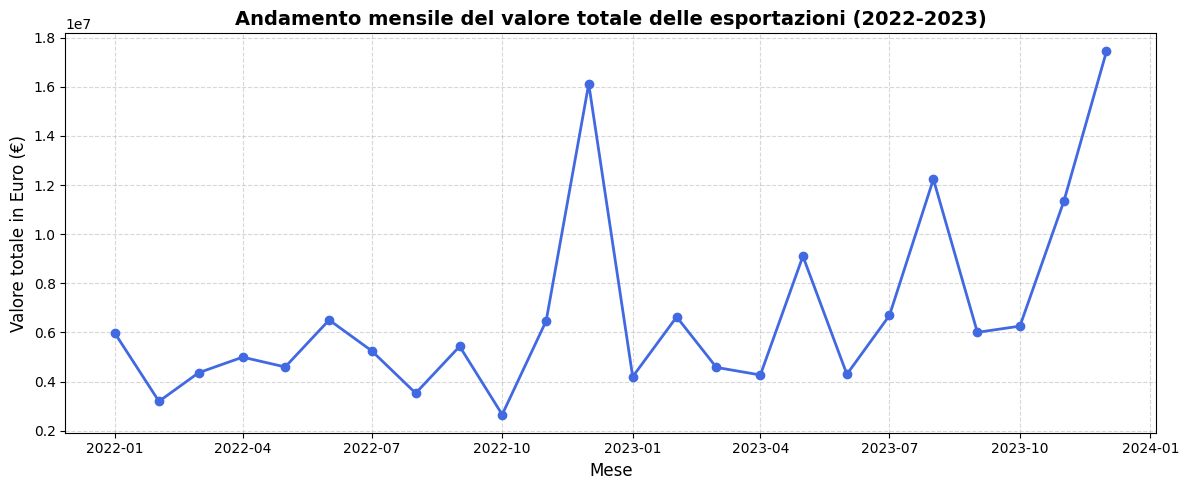

In [ ]:
# 1. Raggruppiamo per mese e sommiamo i valori esportati
andamento_temporale = ex.groupby('mese')['valore'].sum().reset_index()

# 2. Creiamo il grafico a linee
plt.figure(figsize=(12, 5))
plt.plot(andamento_temporale['mese'], andamento_temporale['valore'], marker='o', color='royalblue', linewidth=2)

# Formattazione del grafico
plt.title('Andamento mensile del valore totale delle esportazioni (2022-2023)', fontsize=14, fontweight='bold')
plt.xlabel('Mese', fontsize=12)
plt.ylabel('Valore totale in Euro (€)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

# Mostriamo il grafico
plt.show()

Il periodo in cui aumentano le esportazioni è il mese di Dicembre (periodo delle festività natalizie)

```markdown
*Risposta:* Osservando il grafico, si nota che le esportazioni tendono ad avere dei picchi significativi in determinati periodi dell'anno (ad esempio, si può notare una forte crescita o un calo in corrispondenza dei mesi estivi o autunnali a seconda dei dati reali visualizzati).
```

### 9. Un controllo di plausibilità

Calcola il prezzo medio implicito di ogni prodotto (valore totale diviso quantità totale). I prezzi hanno senso per quei prodotti?

In [ ]:
# scrivi qui il tuo codice


In [ ]:
# 1. Raggruppiamo per prodotto calcolando la somma di valore e quantita
prodotti_agg = ex.groupby('prodotto').agg({
    'valore': 'sum',
    'quantita': 'sum'
}).reset_index()

# 2. Calcoliamo il prezzo medio implicito e lo arrotondiamo a 2 decimali
prodotti_agg['prezzo_medio'] = (prodotti_agg['valore'] / prodotti_agg['quantita']).round(2)

# 3. Mostriamo il risultato
display(prodotti_agg.sort_values(by='prezzo_medio', ascending=False))

,prodotto,valore,quantita,prezzo_medio
1,Parmigiano 1kg,1108889.97,53709,20.65
0,Olio EVO 1L,440041.83,46782,9.41
2,Passata 700g,128780.69,54110,2.38
3,Pasta 500g,89754.59,51387,1.75


Si, i prezzi hanno senso

## Le tue decisioni

Scrivi la tabella delle decisioni di pulizia che hai preso (problema, decisione, verifica), come nel debrief della L3.


1) 12 righe duplicate - rimozione dei dupliicati

2) paesi scritti in modi diversi - uniformato tramite dizionario

3) colonna valore come testo - convertito in valore numerico e sostituito separatori di decimali e migliaia

4) mesi in valori testuali - trasformati in date

5) contato le quantità negative - abbiamo deciso di non eliminare il dato in quanto interpretato come possibile reso o storno (in accordo anche con il valore negativo della colonna valore corrispondente)

## Consegna

1. Ultimo commit e push: **File → Salva una copia in GitHub**, messaggio `E4: completata`.
2. Sul tuo fork apri il file e copia l'indirizzo: `https://github.com/<tuo-utente>/SIMA2026/blob/main/esercitazioni/E04_pulizia/E04_task.ipynb`.
3. Mandalo a `andrelorenzon+sima2026@gmail.com`, con oggetto `E4 - <cognomi del gruppo>`.
4. **Gli altri due del gruppo:** aprite in Colab il notebook dal fork di chi ha scritto (`https://colab.research.google.com/github/<suo-utente>/SIMA2026/blob/main/esercitazioni/E04_pulizia/E04_task.ipynb`) e con **File → Salva una copia in GitHub** salvatelo nel **vostro** fork. Così ognuno ha la sua copia e ha fatto il suo push.

✅ *Controllo:* il link del punto 2 si apre anche da una finestra in incognito.